# 2. Classificação com MFCC, KNN e SVM

**Pergunta:** treinar com aumento de dados por ruído melhora o reconhecimento dos comandos
em ambientes ruidosos, em comparação com treinar só com áudio limpo? E qual classificador,
KNN ou SVM, se sai melhor?

**Desenho do experimento**

| Fator | Níveis |
|---|---|
| Classificador | KNN, SVM (kernel RBF) |
| Treino | só limpo; limpo + ruído a 20, 10 e 0 dB |
| Avaliação | limpo, 20 dB, 10 dB e 0 dB |

- Características: 13 MFCC + delta, resumidos por média e desvio-padrão (52 valores).
- Divisão por locutor, a **mesma** do trabalho de redes neurais (`saida/divisao.csv`).
- Ruídos do MUSAN divididos entre as partições: a avaliação usa ruídos nunca vistos no treino.
- Hiperparâmetros (k do KNN; C e gamma do SVM) escolhidos **só na validação**.
- O teste é consultado uma única vez, no fim (`RODAR_TESTE = True`).
- Métricas: acurácia, precisão, recall e F1 (macro) e matriz de confusão.

In [6]:
# Instalação (Colab). Rode uma vez por sessão.
!pip install -q librosa soundfile scikit-learn pandas matplotlib

In [7]:
from google.colab import drive; drive.mount('/content/drive')
!unzip -q /content/drive/MyDrive/Projetos/Deteccao_Vozes/dados.zip -d /content

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
replace /content/dados/audios/P012_apagar_luz_r2.wav? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace /content/dados/audios/C0029_common_voice_pt_40716013.wav? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace /content/dados/audios/P039_ligar_ventilador_r2.wav? [y]es, [n]o, [A]ll, [N]one, [r]ename: N


In [8]:
import os, glob, time, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, ConfusionMatrixDisplay)

# ---------------- Configuração ----------------
SEED = 42
SR, DUR = 16000, 2.0            # 16 kHz, janela fixa de 2 s
N = int(SR * DUR)               # 32.000 amostras por áudio
SNRS = [20, 10, 0]
CONDS = ["limpo", "20dB", "10dB", "0dB"]

META = "dados/metadata.csv"
AUDIO_DIR = "dados/audios"
NOISE_DIR = "dados/musan/noise"
OUT, FIG = "saida", "figuras"
DIVISAO = f"{OUT}/divisao.csv"
CACHE = f"{OUT}/features_ml.npz"
os.makedirs(OUT, exist_ok=True); os.makedirs(FIG, exist_ok=True)

# A classe "fora" (falas do Common Voice) representa entradas inválidas, como prevê a proposta.
# Com False, o problema fica só com os 6 comandos.
INCLUIR_NEGATIVOS = True
RODAR_TESTE = False             # mude para True apenas uma vez, no fim do projeto

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "grid.linestyle": "--"})

## 2.1 Divisão por locutor

Se `saida/divisao.csv` já existe (criado pelo baseline de redes neurais), ele é reaproveitado.
Assim os dois trabalhos usam exatamente as mesmas partições. Senão, a divisão é criada aqui
com o mesmo procedimento: 60/20/20, separada para comandos e negativos.

In [9]:
meta = pd.read_csv(META)

if os.path.exists(DIVISAO):
    div = pd.read_csv(DIVISAO)[["arquivo", "particao"]]
    meta = meta.merge(div, on="arquivo", how="left")
    faltando = meta["particao"].isna().sum()
    if faltando:
        raise ValueError(f"{faltando} áudios do metadata.csv não estão em {DIVISAO}. "
                         "Apague o arquivo para refazer a divisão (e refaça nos dois trabalhos).")
    print("Divisão reaproveitada de", DIVISAO)
else:
    rng_div = np.random.default_rng(SEED)
    particao = {}
    for _, grupo in meta.groupby("tipo"):
        loc = np.array(sorted(grupo["locutor"].unique()))
        rng_div.shuffle(loc)
        a, b_ = int(round(0.6 * len(loc))), int(round(0.8 * len(loc)))
        particao.update({l: "treino" for l in loc[:a]})
        particao.update({l: "val" for l in loc[a:b_]})
        particao.update({l: "teste" for l in loc[b_:]})
    meta["particao"] = meta["locutor"].map(particao)
    meta.to_csv(DIVISAO, index=False)
    print("Nova divisão salva em", DIVISAO)

if not INCLUIR_NEGATIVOS:
    meta = meta[meta["tipo"] == "comando"].reset_index(drop=True)

(meta.groupby(["particao", "tipo"])
     .agg(audios=("arquivo", "size"), locutores=("locutor", "nunique"))
     .unstack("tipo").reindex(["treino", "val", "teste"]))

Divisão reaproveitada de saida/divisao.csv


audios          locutores         
tipo     comando negativo   comando negativo
particao                                    
treino       312      322        26      121
val           96       93         8       41
teste        108      104         9       40

## 2.2 Pré-processamento, ruído e MFCC

Para cada áudio: mono, 16 kHz, silêncio das pontas removido, 2 s fixos e pico normalizado.
Em seguida são geradas as versões com ruído do MUSAN a 20, 10 e 0 dB de SNR, sempre com
ruídos da própria partição. As características são salvas em cache: as próximas execuções
pulam esta etapa.

In [5]:
def carregar(caminho):
    y, _ = librosa.load(caminho, sr=SR, mono=True)
    y, _ = librosa.effects.trim(y, top_db=30)
    if len(y) >= N:
        s = (len(y) - N) // 2
        y = y[s:s + N]
    else:
        pad = N - len(y)
        y = np.pad(y, (pad // 2, pad - pad // 2))
    return 0.9 * y / (np.max(np.abs(y)) + 1e-9)

def misturar(y, arquivo_ruido, snr_db, rng):
    r, _ = librosa.load(arquivo_ruido, sr=SR, mono=True)
    if len(r) < N:
        r = np.tile(r, N // max(len(r), 1) + 1)
    s = rng.integers(0, len(r) - N + 1)
    r = r[s:s + N]
    voz = y[np.abs(y) > 0.02 * np.max(np.abs(y))]
    p_voz = np.mean(voz ** 2) if len(voz) else np.mean(y ** 2)   # evita média de vetor vazio
    ganho = np.sqrt(p_voz / ((np.mean(r ** 2) + 1e-12) * 10 ** (snr_db / 10)))
    m = y + ganho * r
    return 0.9 * m / (np.max(np.abs(m)) + 1e-9)

def mfcc_stats(y):
    m = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=13, n_fft=400, hop_length=160)
    f = np.vstack([m, librosa.feature.delta(m)])
    return np.concatenate([f.mean(axis=1), f.std(axis=1)])      # 52 valores

def extrair(meta):
    rng = np.random.default_rng(SEED)
    ruidos = sorted(glob.glob(f"{NOISE_DIR}/**/*.wav", recursive=True))
    if len(ruidos) < 5:
        raise FileNotFoundError(f"Poucos ruídos em {NOISE_DIR}: baixe a parte 'noise' do MUSAN.")
    rng.shuffle(ruidos)
    k = len(ruidos)
    ruidos_part = {"treino": ruidos[:int(0.6 * k)], "val": ruidos[int(0.6 * k):int(0.8 * k)],
                   "teste": ruidos[int(0.8 * k):]}
    X, linhas = [], []
    for i, r in enumerate(meta.sort_values("arquivo").itertuples(), 1):
        y = carregar(os.path.join(AUDIO_DIR, r.arquivo))
        X.append(mfcc_stats(y)); linhas.append((r.arquivo, "limpo", ""))
        for snr in SNRS:
            rz = rng.choice(ruidos_part[r.particao])
            X.append(mfcc_stats(misturar(y, rz, snr, rng)))
            linhas.append((r.arquivo, f"{snr}dB", os.path.basename(rz)))
        if i % 100 == 0:
            print(f"  {i}/{len(meta)} áudios")
    return np.array(X, dtype=np.float32), pd.DataFrame(linhas, columns=["arquivo", "cond", "ruido"])

t0 = time.time()
if os.path.exists(CACHE):
    z = np.load(CACHE, allow_pickle=True)
    X = z["X"]; info = pd.DataFrame(z["info"], columns=["arquivo", "cond", "ruido"])
    print("Características carregadas do cache", CACHE)
else:
    X, info = extrair(meta)
    np.savez(CACHE, X=X, info=info.values)
    info.to_csv(f"{OUT}/registro_ruido_ml.csv", index=False)
print(f"Extração: {time.time() - t0:.1f} s")

df = info.merge(meta[["arquivo", "locutor", "rotulo", "tipo", "particao"]], on="arquivo", how="left")
df = df[df["particao"].notna()]                   # caso o cache tenha áudios removidos depois
X = X[df.index.values]; df = df.reset_index(drop=True)

ok = np.isfinite(X).all(axis=1)
if not ok.all():
    print(f"Removendo {(~ok).sum()} amostras com NaN/inf")
    X, df = X[ok], df[ok].reset_index(drop=True)
print("Matriz de características:", X.shape)

  100/1035 áudios
  200/1035 áudios
  300/1035 áudios
  400/1035 áudios
  500/1035 áudios
  600/1035 áudios
  700/1035 áudios
  800/1035 áudios
  900/1035 áudios
  1000/1035 áudios
Extração: 90.0 s
Matriz de características: (4140, 52)


## 2.3 Funções de treino e avaliação

O `StandardScaler` fica dentro do pipeline, então a média e o desvio de cada característica
são calculados só com o treino. Isso importa muito para o KNN e o SVM, que dependem de
distâncias.

In [10]:
CLASSES = sorted(df["rotulo"].unique())

def mascara(particao, treino=None, cond=None):
    m = df["particao"] == particao
    if treino == "limpo" or cond is not None:
        m &= df["cond"] == (cond or "limpo")
    return m.values

def modelo(nome, params):
    if nome == "KNN":
        clf = KNeighborsClassifier(n_neighbors=params["k"], weights=params["pesos"])
    else:
        clf = SVC(kernel="rbf", C=params["C"], gamma=params["gamma"])
    return make_pipeline(StandardScaler(), clf)

def metricas(y, p):
    prec, rec, f1, _ = precision_recall_fscore_support(y, p, labels=CLASSES,
                                                       average="macro", zero_division=0)
    return dict(acuracia=accuracy_score(y, p), precisao=prec, recall=rec, f1=f1)

GRADES = {
    "KNN": [dict(k=k, pesos=w) for k in [1, 3, 5, 7, 9, 11, 15] for w in ["uniform", "distance"]],
    "SVM": [dict(C=C, gamma=g) for C in [0.1, 1, 10, 100] for g in ["scale", 0.001, 0.01, 0.1]],
}
TREINOS = {"limpo": "Só limpo", "aumentado": "Limpo + ruído"}
print("Classes:", CLASSES)

Classes: ['abrir_cortina', 'acender_luz', 'apagar_luz', 'desligar_ventilador', 'fechar_cortina', 'fora', 'ligar_ventilador']


## 2.4 Escolha dos hiperparâmetros na validação

Para cada classificador e cada regime de treino, todas as combinações da grade são treinadas
e avaliadas na validação, juntando as quatro condições de ruído. Fica a de maior F1 macro.

In [11]:
X_val, y_val = X[mascara("val")], df.loc[mascara("val"), "rotulo"].values
busca, melhores = [], {}

for nome, treino in itertools.product(GRADES, TREINOS):
    m_tr = mascara("treino", treino=treino)
    X_tr, y_tr = X[m_tr], df.loc[m_tr, "rotulo"].values
    for params in GRADES[nome]:
        f1 = metricas(y_val, modelo(nome, params).fit(X_tr, y_tr).predict(X_val))["f1"]
        busca.append(dict(modelo=nome, treino=treino, params=str(params), f1_val=f1))
    sub = [r for r in busca if r["modelo"] == nome and r["treino"] == treino]
    melhor = max(sub, key=lambda r: r["f1_val"])
    melhores[(nome, treino)] = eval(melhor["params"])
    print(f"{nome:3s} | {TREINOS[treino]:14s} | {melhor['params']:40s} | F1 val = {melhor['f1_val']:.3f}")

pd.DataFrame(busca).to_csv(f"{OUT}/busca_hiperparametros.csv", index=False)

KNN | Só limpo       | {'k': 9, 'pesos': 'distance'}            | F1 val = 0.279
KNN | Limpo + ruído  | {'k': 15, 'pesos': 'distance'}           | F1 val = 0.325
SVM | Só limpo       | {'C': 100, 'gamma': 0.001}               | F1 val = 0.332
SVM | Limpo + ruído  | {'C': 10, 'gamma': 'scale'}              | F1 val = 0.389


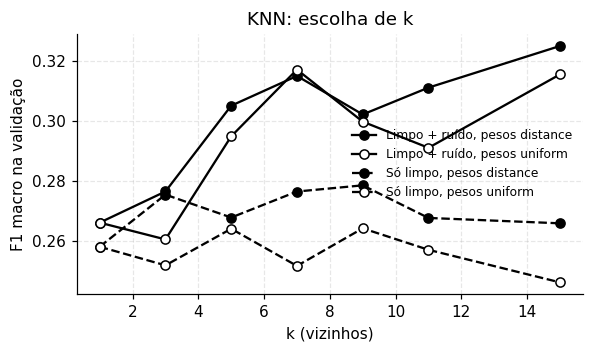

In [12]:
# Curva de validação do KNN: F1 em função de k (pesos 'distance')
bk = pd.DataFrame(busca)
bk = bk[bk["modelo"] == "KNN"].copy()
bk["k"] = bk["params"].apply(lambda s: eval(s)["k"])
bk["pesos"] = bk["params"].apply(lambda s: eval(s)["pesos"])

fig, ax = plt.subplots(figsize=(5.5, 3.3))
for (treino, pesos), g in bk.groupby(["treino", "pesos"]):
    ax.plot(g["k"], g["f1_val"], marker="o", color="black",
            linestyle="-" if treino == "aumentado" else "--",
            markerfacecolor="black" if pesos == "distance" else "white",
            label=f"{TREINOS[treino]}, pesos {pesos}")
ax.set_xlabel("k (vizinhos)"); ax.set_ylabel("F1 macro na validação")
ax.set_title("KNN: escolha de k"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/knn_escolha_k.png"); plt.show()

## 2.5 Resultados na validação por condição de ruído

Com os hiperparâmetros escolhidos, cada modelo é avaliado separadamente no áudio limpo e a
20, 10 e 0 dB. O tempo de treino também é registrado.

In [13]:
def avaliar_em(particao):
    linhas, finais = [], {}
    for (nome, treino), params in melhores.items():
        m_tr = mascara("treino", treino=treino)
        t0 = time.time()
        clf = modelo(nome, params).fit(X[m_tr], df.loc[m_tr, "rotulo"].values)
        t_treino = time.time() - t0
        finais[(nome, treino)] = clf
        for cond in CONDS:
            m = mascara(particao, cond=cond)
            t1 = time.time(); p = clf.predict(X[m]); t_pred = (time.time() - t1) / m.sum() * 1000
            linhas.append(dict(modelo=nome, treino=TREINOS[treino], cond=cond,
                               **metricas(df.loc[m, "rotulo"].values, p),
                               tempo_treino_s=t_treino, ms_por_audio=t_pred))
    return pd.DataFrame(linhas), finais

res_val, finais = avaliar_em("val")
res_val.to_csv(f"{OUT}/resultados_ml_val.csv", index=False)

tabela = res_val.pivot_table(index=["modelo", "treino"], columns="cond", values="f1")[CONDS]
print("F1 macro na validação")
display(tabela.round(3))
display(res_val.round(3))

F1 macro na validação


cond                  limpo   20dB   10dB    0dB
modelo treino                                   
KNN    Limpo + ruído  0.423  0.361  0.248  0.249
       Só limpo       0.386  0.308  0.242  0.175
SVM    Limpo + ruído  0.506  0.410  0.374  0.227
       Só limpo       0.453  0.419  0.272  0.180

,modelo,treino,cond,acuracia,precisao,recall,f1,tempo_treino_s,ms_por_audio
0,KNN,Só limpo,limpo,0.587,0.380,0.407,0.386,0.007,0.029
1,KNN,Só limpo,20dB,0.381,0.336,0.332,0.308,0.007,0.028
2,KNN,Só limpo,10dB,0.302,0.266,0.295,0.242,0.007,0.027
3,KNN,Só limpo,0dB,0.217,0.204,0.218,0.175,0.007,0.027
4,KNN,Limpo + ruído,limpo,0.603,0.450,0.426,0.423,0.009,0.059
5,KNN,Limpo + ruído,20dB,0.497,0.386,0.359,0.361,0.009,0.059
6,KNN,Limpo + ruído,10dB,0.450,0.270,0.241,0.248,0.009,0.059
7,KNN,Limpo + ruído,0dB,0.471,0.282,0.240,0.249,0.009,0.059
8,SVM,Só limpo,limpo,0.646,0.468,0.476,0.453,0.049,0.067
9,SVM,Só limpo,20dB,0.556,0.422,0.450,0.419,0.049,0.068


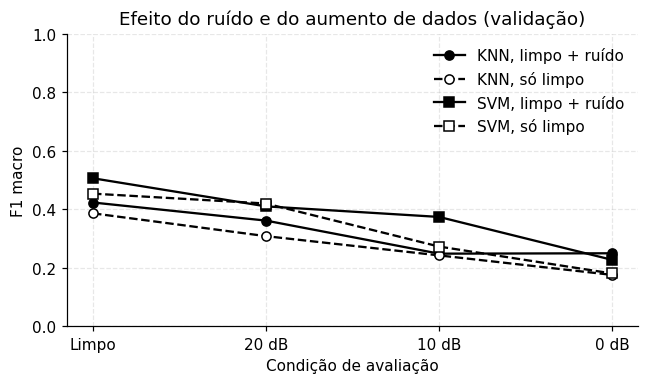

In [14]:
# F1 em função do ruído: uma linha por modelo e regime de treino
eixo_x = ["Limpo", "20 dB", "10 dB", "0 dB"]
estilos = {("KNN", "Só limpo"): ("--", "o", "white"), ("KNN", "Limpo + ruído"): ("-", "o", "black"),
           ("SVM", "Só limpo"): ("--", "s", "white"), ("SVM", "Limpo + ruído"): ("-", "s", "black")}

fig, ax = plt.subplots(figsize=(6, 3.6))
for (nome, treino), g in res_val.groupby(["modelo", "treino"]):
    ls, mk, fc = estilos[(nome, treino)]
    g = g.set_index("cond").loc[CONDS]
    ax.plot(eixo_x, g["f1"], linestyle=ls, marker=mk, color="black", markerfacecolor=fc,
            label=f"{nome}, {treino.lower()}")
ax.set_ylabel("F1 macro"); ax.set_xlabel("Condição de avaliação")
ax.set_title("Efeito do ruído e do aumento de dados (validação)")
ax.set_ylim(0, 1); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(f"{FIG}/f1_por_ruido_val.png"); plt.show()

## 2.6 Matrizes de confusão

Mostram quais comandos são mais confundidos. Pares como "ligar" e "desligar" o ventilador,
que diferem só na primeira sílaba, são os candidatos naturais.

Melhor na validação: SVM, treino limpo + ruído (F1 médio = 0.379)


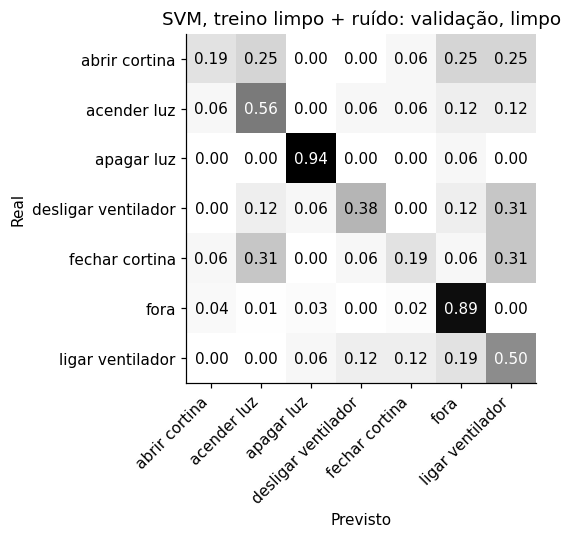

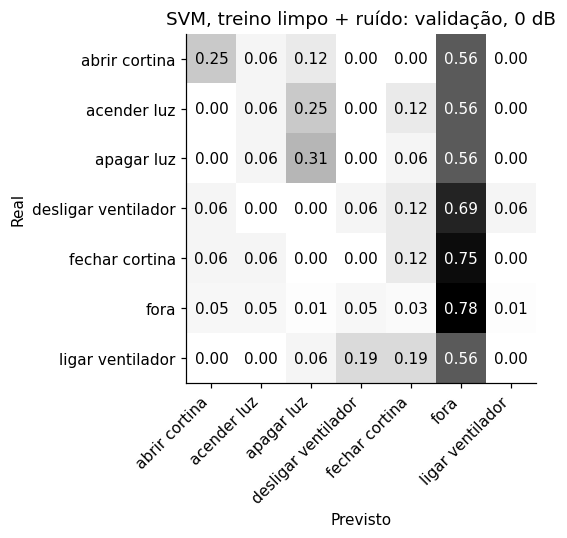

In [15]:
def matriz(clf, particao, cond, titulo, arquivo):
    m = mascara(particao, cond=cond)
    y, p = df.loc[m, "rotulo"].values, clf.predict(X[m])
    nomes = [c.replace("_", " ") for c in CLASSES]
    cm = confusion_matrix(y, p, labels=CLASSES, normalize="true")
    fig, ax = plt.subplots(figsize=(5.8, 5))
    ConfusionMatrixDisplay(cm, display_labels=nomes).plot(ax=ax, cmap="Greys", values_format=".2f",
                                                          colorbar=False)
    ax.set_title(titulo); ax.set_xlabel("Previsto"); ax.set_ylabel("Real")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right"); ax.grid(False)
    plt.tight_layout(); plt.savefig(f"{FIG}/{arquivo}.png"); plt.show()

# Melhor modelo na validação (média do F1 nas quatro condições)
media = res_val.groupby(["modelo", "treino"])["f1"].mean()
nome_m, treino_m = media.idxmax()
chave = (nome_m, {v: k for k, v in TREINOS.items()}[treino_m])
print(f"Melhor na validação: {nome_m}, treino {treino_m.lower()} (F1 médio = {media.max():.3f})")

for cond, rot in [("limpo", "limpo"), ("0dB", "0 dB")]:
    matriz(finais[chave], "val", cond, f"{nome_m}, treino {treino_m.lower()}: validação, {rot}",
           f"confusao_val_{cond}")

## 2.7 Teste final (rodar uma única vez)

Só mude `RODAR_TESTE` para `True` quando todas as escolhas estiverem feitas na validação.
Olhar o teste e depois mudar hiperparâmetros invalida o resultado.

F1 macro no TESTE


cond                  limpo   20dB   10dB    0dB
modelo treino                                   
KNN    Limpo + ruído  0.491  0.334  0.270  0.227
       Só limpo       0.434  0.317  0.261  0.184
SVM    Limpo + ruído  0.486  0.451  0.319  0.239
       Só limpo       0.542  0.393  0.273  0.169

,modelo,treino,cond,acuracia,precisao,recall,f1,tempo_treino_s,ms_por_audio
0,KNN,Só limpo,limpo,0.594,0.484,0.449,0.434,0.009,0.028
1,KNN,Só limpo,20dB,0.429,0.328,0.342,0.317,0.009,0.085
2,KNN,Só limpo,10dB,0.307,0.277,0.312,0.261,0.009,0.039
3,KNN,Só limpo,0dB,0.269,0.202,0.229,0.184,0.009,0.038
4,KNN,Limpo + ruído,limpo,0.632,0.545,0.486,0.491,0.015,0.057
5,KNN,Limpo + ruído,20dB,0.509,0.361,0.332,0.334,0.015,0.111
6,KNN,Limpo + ruído,10dB,0.434,0.285,0.264,0.270,0.015,0.146
7,KNN,Limpo + ruído,0dB,0.458,0.243,0.225,0.227,0.015,0.057
8,SVM,Só limpo,limpo,0.693,0.592,0.556,0.542,0.157,0.116
9,SVM,Só limpo,20dB,0.552,0.501,0.436,0.393,0.157,0.131


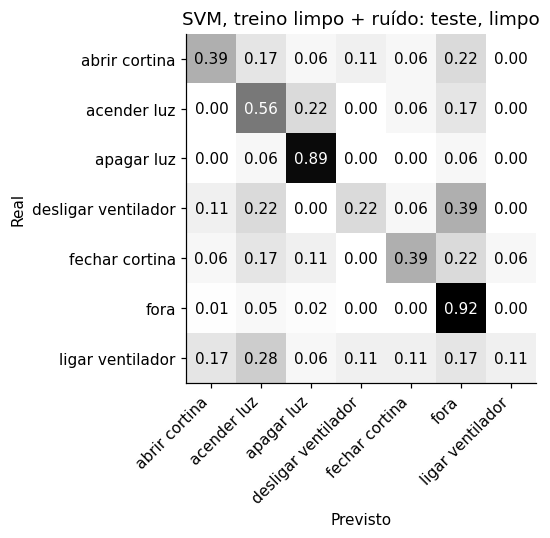

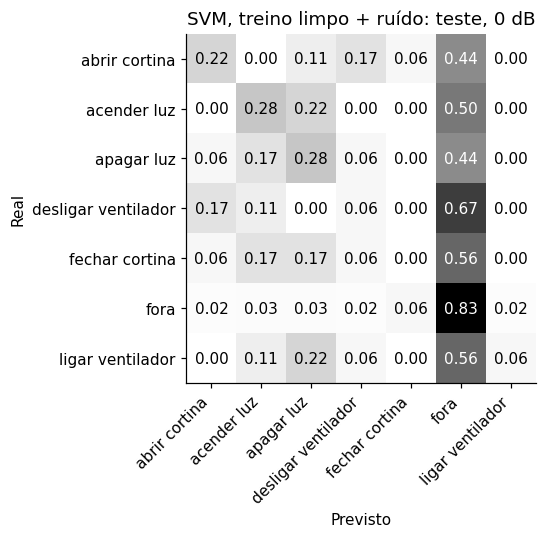

In [17]:
if True:
    res_teste, finais_teste = avaliar_em("teste")
    res_teste.to_csv(f"{OUT}/resultados_ml_teste.csv", index=False)
    print("F1 macro no TESTE")
    display(res_teste.pivot_table(index=["modelo", "treino"], columns="cond", values="f1")[CONDS].round(3))
    display(res_teste.round(3))
    for cond, rot in [("limpo", "limpo"), ("0dB", "0 dB")]:
        matriz(finais_teste[chave], "teste", cond, f"{nome_m}, treino {treino_m.lower()}: teste, {rot}",
               f"confusao_teste_{cond}")
else:
    print("Teste não executado (RODAR_TESTE = False).")

In [18]:
DESTINO = "/content/drive/MyDrive/Projetos/Deteccao_Vozes"
!cp -r /content/figuras /content/saida "$DESTINO/"
!ls "$DESTINO"

common-voice  dados.zip  figuras  musan  saida
